# Which grounding line? A check against ICESat-2

The plate is clamped where `lake_routing.floating_mask` says the ice stops floating, so the grounding line (GL) sets the boundary condition. This notebook scores published GL products on the routing domain against an **independent** observation, the ICESat-2 grounding-zone points of Li et al. (2022), which locate tidal flexure along repeat tracks (2019–2020):

* **F**: landward limit of tidal flexure (closest to the true GL; where a clamped plate should be fixed),
* **H**: inshore limit of hydrostatic equilibrium (must be floating),
* **Ib**: break in surface slope.

Candidates, all rasterised onto the 32 m DEM grid:

| name | product |
|---|---|
| MEaSUREs raster | `data/Mask_Antarctica_v02.tif`: MEaSUREs Antarctic Boundaries v2 (NSIDC-0709) at 500 m. The previous default. |
| MEaSUREs vector | the same product's ice-boundary polygons. **The new default** (`floating_mask(grid)`). Needs an Earthdata token. |
| ADD v7.13 | SCAR Antarctic Digital Database high-resolution coastline polygons (open, CC BY 4.0). On Nivlisen its GL is from ASAID (Bindschadler et al. 2011). |

If the MEaSUREs InSAR GL lines (NSIDC-0498 v2.1, Rignot et al. 2016) are in `data/measures_insar_gl_v2/`, the notebook also measures how closely each mask follows them. Change `DEM_FILE` to check another shelf.

In [1]:
import sys, urllib.request, zipfile
from pathlib import Path
sys.path.insert(0, "..")
import numpy as np, pandas as pd, xarray as xr, rioxarray, geopandas as gpd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from rasterio import features
from scipy import ndimage
import lake_routing as lr

REPO = lr.REPO
DEM_FILE = REPO / "python/notebooks/Nivlisen_32m_REMA_v2.tif"
dem = xr.open_dataarray(DEM_FILE, engine="rasterio").squeeze(drop=True)
dx = abs(float(dem.x[1] - dem.x[0]))
b = dem.rio.bounds(); T = dem.rio.transform(); shape = dem.shape
print(f"grid {shape}, dx = {dx:g} m")

grid (3700, 3202), dx = 32 m


/usr/local/lib/python3.13/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


## Download the open data (cached in `data/`)

In [2]:
def fetch(url, out):
    out = Path(out)
    if not out.exists():
        out.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, out)
    return out

IS2 = "https://data.bris.ac.uk/datasets/bnqqyngt89eo26qk8keckglww/"
is2 = {P: pd.read_csv(fetch(IS2 + f"ICESat2_{P}.csv", REPO / f"data/icesat2_grounding_zone/ICESat2_{P}.csv"))
       for P in "FHI"}
ADD_ZIP = ("https://ramadda.data.bas.ac.uk/repository/entry/get/add_coastline_high_res_polygon_v7_13.shp.zip?"
           "entryid=synth%3A1c81cf24-576f-43df-be72-a5c7dbb51ffb%3AL2FkZF9jb2FzdGxpbmVfaGlnaF9yZXNfcG9seWdvbl92N18xMy5zaHAuemlw")
add_dir = REPO / "data/add_coastline_v7_13"
z = fetch(ADD_ZIP, add_dir / "add_coastline_high_res_polygon_v7_13.shp.zip")
if not (add_dir / "add_coastline_high_res_polygon_v7_13.shp").exists():
    zipfile.ZipFile(z).extractall(add_dir)
print({P: len(v) for P, v in is2.items()}, "ICESat-2 points (whole continent)")

{'F': 21346, 'H': 18149, 'I': 36765} ICESat-2 points (whole continent)


## The candidate masks

In [3]:
def burn(geoms):
    return features.rasterize(((g, 1) for g in geoms), out_shape=shape, transform=T, dtype="uint8").astype(bool)

ib = gpd.read_file(lr.MEASURES_DIR / f"{lr.MEASURES_FILE}.shp", bbox=b)
ice = burn(ib.geometry)                      # any ice (floating or grounded); the rest is ocean
add = gpd.read_file(add_dir / "add_coastline_high_res_polygon_v7_13.shp", bbox=b)
masks = {
    "MEaSUREs raster (500 m)": lr.floating_mask(dem, source="measures_raster").values & ice,
    "MEaSUREs vector": lr.floating_mask(dem).values,
    "ADD v7.13": burn(add[add.surface.isin(["ice shelf", "ice tongue"])].geometry),
}
for k, m in masks.items():
    print(f"{k:24s} floating area {m.sum() * dx * dx / 1e6:7.0f} km2")

MEaSUREs raster (500 m)  floating area    5874 km2
MEaSUREs vector          floating area    5919 km2
ADD v7.13                floating area    5975 km2


## Scores

For each mask the GL is the set of floating cells that touch grounded ice (ice fronts are excluded). Only ICESat-2 points inside the domain and more than 3 km from open ocean are used. Smaller distances are better. Every H point should be on the floating side; F lies at or just landward of the true GL, so a share well below 50% on the floating side means the mask's GL is too far seaward.

In [4]:
tr = Transformer.from_crs(4326, 3031, always_xy=True)
far_from_ocean = ndimage.distance_transform_edt(ice) * dx > 3000
pts = {}
for P, d in is2.items():
    x, y = tr.transform(d.lon.values, d.lat.values)
    j = np.floor((x - b[0]) / dx).astype(int); i = np.floor((b[3] - y) / dx).astype(int)
    ok = (i >= 0) & (i < shape[0]) & (j >= 0) & (j < shape[1])
    i, j, x, y = i[ok], j[ok], x[ok], y[ok]
    k = far_from_ocean[i, j]
    pts[P] = (i[k], j[k], x[k], y[k])

def gl(f):
    return f & ndimage.binary_dilation(ice & ~f)

rows = []
for name, f in masks.items():
    dist = ndimage.distance_transform_edt(~gl(f)) * dx
    r = {"mask": name}
    for P in "FHI":
        i, j = pts[P][:2]
        r[f"{P} n"] = len(i)
        r[f"{P} median dist (m)"] = np.median(dist[i, j])
        r[f"{P} p90 dist (m)"] = np.percentile(dist[i, j], 90)
        r[f"{P} on floating side"] = f[i, j].mean()
    rows.append(r)
scores = pd.DataFrame(rows).set_index("mask")
scores[[c for c in scores.columns if c.startswith("F") or c.startswith("H")]].round(2)

,F n,F median dist (m),F p90 dist (m),F on floating side,H n,H median dist (m),H p90 dist (m),H on floating side
mask,,,,,,,,
MEaSUREs raster (500 m),113,303.58,685.84,0.71,100,2788.76,5820.09,1.00
MEaSUREs vector,113,316.78,886.00,0.75,100,3175.41,5668.20,1.00
ADD v7.13,113,340.16,1324.53,0.59,100,2866.90,5561.79,0.92


In [5]:
insar_file = REPO / "data/measures_insar_gl_v2/InSAR_GL_Antarctica_v02.1.gpkg"
if insar_file.exists():
    insar = gpd.read_file(insar_file, bbox=b)
    line = features.rasterize(((g, 1) for g in insar.geometry), out_shape=shape, transform=T,
                              all_touched=True, dtype="uint8").astype(bool)
    dl = ndimage.distance_transform_edt(~line) * dx
    print(f"{len(insar)} InSAR GL lines in the domain: " + ", ".join(
        f"{s} {', '.join(map(str, sorted(g.Year.unique())))}" for s, g in insar.groupby("Sensor")))
    for name, f in masks.items():
        v = dl[gl(f)]
        print(f"{name:24s} GL cells within 100 m of an InSAR line: {np.mean(v < 100):.0%}   (median {np.median(v):.0f} m)")
else:
    insar = None
    print("InSAR GL (NSIDC-0498) not downloaded; skipping")

14 InSAR GL lines in the domain: PALSAR 2007, RSAT 2000, Sentinel-1 2016, 2018, 2019
MEaSUREs raster (500 m)  GL cells within 100 m of an InSAR line: 60%   (median 64 m)
MEaSUREs vector          GL cells within 100 m of an InSAR line: 88%   (median 32 m)


ADD v7.13                GL cells within 100 m of an InSAR line: 39%   (median 320 m)


## Where they disagree

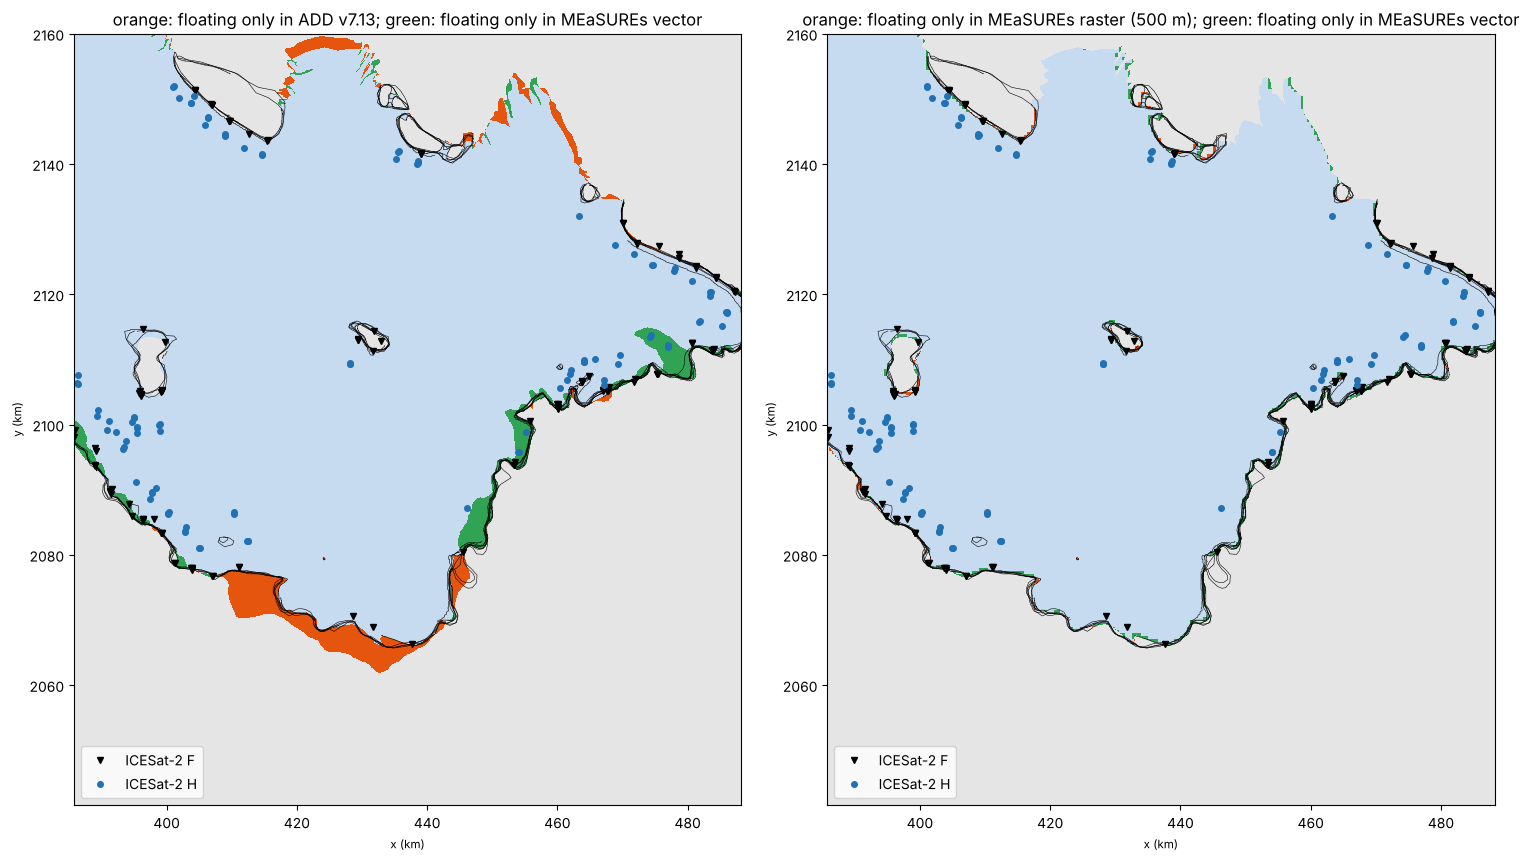

In [6]:
old, vec, adm = masks.values()
fig, ax = plt.subplots(1, 2, figsize=(15, 8.5), constrained_layout=True)
ext = [b[0] / 1e3, b[2] / 1e3, b[1] / 1e3, b[3] / 1e3]
cmap = ListedColormap(["#e5e5e5", "#c6dbef", "#e6550d", "#31a354"])
for a, (other, title) in zip(ax, [(adm, "ADD v7.13"), (old, "MEaSUREs raster (500 m)")]):
    c = np.zeros(shape); c[vec & other] = 1; c[other & ~vec] = 2; c[vec & ~other] = 3
    a.imshow(c, cmap=cmap, vmin=0, vmax=3, extent=ext, interpolation="nearest")
    if insar is not None:
        insar.geometry.scale(1e-3, 1e-3, origin=(0, 0)).plot(ax=a, color="k", lw=0.4)
    for P, mk, col in [("F", "v", "k"), ("H", "o", "#2171b5")]:
        a.plot(pts[P][2] / 1e3, pts[P][3] / 1e3, mk, color=col, ms=4, label=f"ICESat-2 {P}")
    a.set(xlim=ext[:2], ylim=ext[2:], xlabel="x (km)", ylabel="y (km)", aspect="equal",
          title=f"orange: floating only in {title}; green: floating only in MEaSUREs vector")
    a.legend(loc="lower left")
plt.show()

## Conclusions (Nivlisen)

* **ADD v7.13 is worse here.** Its ASAID grounding line is ~5 km off in two places: it grounds the eastern inlets, where ICESat-2 H points (which must be afloat) sit, and it puts the southern GL ~5 km inland of the ICESat-2 F points and the InSAR lines. Its F distances have the largest 90th percentile, and only 39% of its GL cells lie within 100 m of an InSAR line.
* **The MEaSUREs vector and raster carry the same line**, which is the InSAR grounding line (NSIDC-0498) compiled by Mouginot et al. The vector follows the InSAR lines much more closely (88% of GL cells within 100 m, against 60% for the raster) and removes the 500 m staircase. The two masks differ by ~100 km² (≈2% of the shelf), almost all within a few hundred metres of the GL.
* **Against ICESat-2 the vector is no better than the raster** (F median 317 m vs 304 m; 90th percentile 886 m vs 686 m). The gain from the vector is fidelity to the InSAR line it is built from, not better agreement with ICESat-2.
* **Both MEaSUREs masks sit ~300 m (median) from the ICESat-2 F points, and ~70% of F points fall on their floating side**, i.e. the MEaSUREs GL is mostly a little landward of where ICESat-2 sees flexure begin. That is not resolution: it reflects up to 20 years between the InSAR (2000–2019) and ICESat-2 (2019–2020) observations, tide-dependent migration of the grounding zone, and the different flexure limits each method picks. Treat the GL position as uncertain by a few hundred metres (≈0.3ℓ for 400 m thick ice) when interpreting flexure near it.

**Decision:** `floating_mask` now uses the MEaSUREs vector by default (`source="measures_vector"`) and falls back to the 500 m raster when the files cannot be downloaded.

**References**
* Li, T., Dawson, G. J., Chuter, S. J. & Bamber, J. L. (2022). A high-resolution Antarctic grounding zone product from ICESat-2 laser altimetry. *ESSD* 14, 535–557. Data: doi:10.5523/bris.bnqqyngt89eo26qk8keckglww.
* Mouginot, J., Scheuchl, B. & Rignot, E. (2017). MEaSUREs Antarctic Boundaries for IPY 2007–2009 from Satellite Radar, Version 2. NSIDC-0709, doi:10.5067/AXE4121732AD.
* Rignot, E., Mouginot, J. & Scheuchl, B. (2016). MEaSUREs Antarctic Grounding Line from Differential Satellite Radar Interferometry, Version 2. NSIDC-0498, doi:10.5067/IKBWW4RYHF1Q.
* Gerrish, L. et al. (2026). High resolution vector polygons of the Antarctic coastline (v7.13). UK Polar Data Centre, doi:10.5285/1c81cf24-576f-43df-be72-a5c7dbb51ffb.
* Bindschadler, R. et al. (2011). Getting around Antarctica: new high-resolution mappings of the grounded and freely-floating boundaries of the Antarctic ice sheet created for the International Polar Year. *The Cryosphere* 5, 569–588.